<a href="https://colab.research.google.com/github/fathimanoorjahan03-afk/ROADSHIELD/blob/main/Road_Shield_Model_Training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Step 1 – Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Step 2 – Load Preprocessed Data

save_path = '/content/drive/MyDrive/Main project/notebooks/processed_data'

X_train_processed = joblib.load(save_path + '/X_train.pkl')
X_test_processed = joblib.load(save_path + '/X_test.pkl')

y_train = joblib.load(save_path + '/y_train.pkl')
y_test = joblib.load(save_path + '/y_test.pkl')

preprocessor = joblib.load(save_path + '/preprocessor.pkl')

print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training shape: (205185, 144)
Testing shape: (101525, 144)
Training target shape: (205185,)
Testing target shape: (101525,)


In [ ]:
# Step 3 – Target Distribution

print("Training target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training target distribution:
collision_severity
3    155156
2     47005
1      3024
Name: count, dtype: int64

Testing target distribution:
collision_severity
3    74881
2    25191
1     1453
Name: count, dtype: int64


In [ ]:
# Step 4 – Train Validation Split

from sklearn.model_selection import train_test_split

X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train_processed,
    y_train,
    test_size=0.2,
    stratify=y_train,
    random_state=42
)

print("Sub-training shape:", X_subtrain.shape)
print("Validation shape:", X_val.shape)

Sub-training shape: (164148, 144)
Validation shape: (41037, 144)


In [ ]:
# Step 1 – Import Libraries

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import time

In [ ]:
# Step 2 – Logistic Regression Model

log_model = LogisticRegression(
    solver='saga',
    max_iter=200,
    tol=0.001,
    class_weight='balanced',
    random_state=42
)

# Train the model
start_time = time.time()

log_model.fit(X_subtrain, y_subtrain)

end_time = time.time()

print("Logistic Regression training completed!")
print("Training time:", round((end_time - start_time) / 60, 2), "minutes")
print("Iterations:", log_model.n_iter_)

Logistic Regression training completed!
Training time: 0.99 minutes
Iterations: [200]


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [ ]:
# Step 3 – Validation Predictions

y_val_pred = log_model.predict(X_val)

print("Validation predictions completed!")

Validation predictions completed!


In [ ]:
# Step 5 – Model Evaluation

accuracy = accuracy_score(y_val, y_val_pred)
macro_f1 = f1_score(y_val, y_val_pred, average='macro')
weighted_f1 = f1_score(y_val, y_val_pred, average='weighted')

print("Accuracy:", round(accuracy, 4))
print("Macro F1-score:", round(macro_f1, 4))
print("Weighted F1-score:", round(weighted_f1, 4))

print("\nClassification Report:\n")

print(classification_report(
    y_val,
    y_val_pred,
    labels=[1, 2, 3],
    target_names=['Fatal', 'Serious', 'Slight'],
    zero_division=0
))

Accuracy: 0.4633
Macro F1-score: 0.3302
Weighted F1-score: 0.5403

Classification Report:

              precision    recall  f1-score   support

       Fatal       0.04      0.65      0.07       605
     Serious       0.27      0.33      0.30      9401
      Slight       0.83      0.50      0.62     31031

    accuracy                           0.46     41037
   macro avg       0.38      0.49      0.33     41037
weighted avg       0.69      0.46      0.54     41037



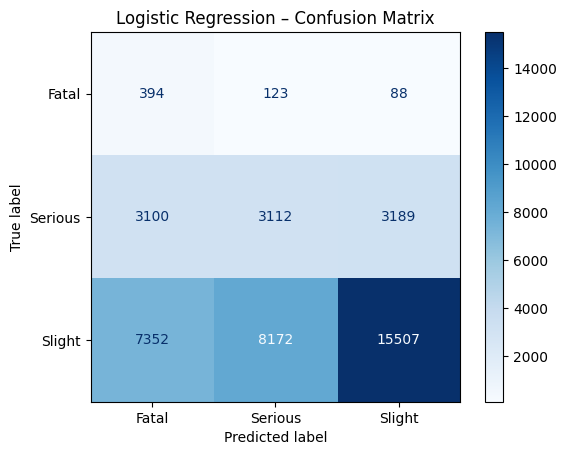

In [ ]:
# Step 6 – Confusion Matrix

cm = confusion_matrix(
    y_val,
    y_val_pred,
    labels=[1, 2, 3]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Fatal', 'Serious', 'Slight']
)

disp.plot(cmap='Blues', values_format='d')

plt.title('Logistic Regression – Confusion Matrix')
plt.show()

In [ ]:
# Step 7 – Store Model Results

log_results = {
    'Model': 'Logistic Regression',
    'Accuracy': accuracy,
    'Macro F1': macro_f1,
    'Weighted F1': weighted_f1
}

print(log_results)

{'Model': 'Logistic Regression', 'Accuracy': 0.463313595048371, 'Macro F1': 0.33017141151650575, 'Weighted F1': 0.5403175280313957}


In [ ]:
# Model 2 – Decision Tree

from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    max_depth=20,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=42
)

# Train the model
start_time = time.time()

dt_model.fit(X_subtrain, y_subtrain)

end_time = time.time()

print("Decision Tree training completed!")
print("Training time:",
      round((end_time - start_time) / 60, 2), "minutes")

Decision Tree training completed!
Training time: 0.45 minutes


In [ ]:
# Validation Predictions

y_val_pred_dt = dt_model.predict(X_val)

print("Decision Tree predictions completed!")

Decision Tree predictions completed!


In [ ]:
# Model Evaluation

dt_accuracy = accuracy_score(y_val, y_val_pred_dt)

dt_macro_f1 = f1_score(
    y_val, y_val_pred_dt, average='macro'
)

dt_weighted_f1 = f1_score(
    y_val, y_val_pred_dt, average='weighted'
)

print("Accuracy:", round(dt_accuracy, 4))
print("Macro F1:", round(dt_macro_f1, 4))
print("Weighted F1:", round(dt_weighted_f1, 4))

print("\nClassification Report:\n")

print(classification_report(
    y_val,
    y_val_pred_dt,
    labels=[1, 2, 3],
    target_names=['Fatal', 'Serious', 'Slight'],
    zero_division=0
))

Accuracy: 0.5386
Macro F1: 0.3541
Weighted F1: 0.5835

Classification Report:

              precision    recall  f1-score   support

       Fatal       0.04      0.21      0.06       605
     Serious       0.27      0.43      0.33      9401
      Slight       0.80      0.58      0.67     31031

    accuracy                           0.54     41037
   macro avg       0.37      0.41      0.35     41037
weighted avg       0.66      0.54      0.58     41037



In [ ]:
from sklearn.ensemble import RandomForestClassifier
import time

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

rf_model.fit(X_subtrain, y_subtrain)

end_time = time.time()

print("Random Forest training completed!")
print("Training time:", round((end_time - start_time) / 60, 2), "minutes")

Random Forest training completed!
Training time: 2.94 minutes


In [ ]:
y_val_pred_rf = rf_model.predict(X_val)


rf_accuracy = accuracy_score(y_val, y_val_pred_rf)
rf_macro_f1 = f1_score(y_val, y_val_pred_rf, average='macro')
rf_weighted_f1 = f1_score(y_val, y_val_pred_rf, average='weighted')

print("Accuracy:", round(rf_accuracy, 4))
print("Macro F1:", round(rf_macro_f1, 4))
print("Weighted F1:", round(rf_weighted_f1, 4))

print("\nClassification Report:\n")

print(classification_report(
    y_val,
    y_val_pred_rf,
    labels=[1, 2, 3],
    target_names=['Fatal', 'Serious', 'Slight'],
    zero_division=0
))

Accuracy: 0.6208
Macro F1: 0.4037
Weighted F1: 0.6495

Classification Report:

              precision    recall  f1-score   support

       Fatal       0.06      0.26      0.10       605
     Serious       0.32      0.42      0.36      9401
      Slight       0.82      0.69      0.75     31031

    accuracy                           0.62     41037
   macro avg       0.40      0.46      0.40     41037
weighted avg       0.69      0.62      0.65     41037



In [ ]:
from xgboost import XGBClassifier
import time

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='multi:softprob',
    num_class=3,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

xgb_model.fit(X_subtrain, y_subtrain - 1)

end_time = time.time()

print("XGBoost training completed!")
print("Training time:", round((end_time - start_time) / 60, 2), "minutes")

XGBoost training completed!
Training time: 0.19 minutes


In [ ]:
y_val_pred_xgb = xgb_model.predict(X_val) + 1


xgb_accuracy = accuracy_score(y_val, y_val_pred_xgb)
xgb_macro_f1 = f1_score(y_val, y_val_pred_xgb, average='macro')
xgb_weighted_f1 = f1_score(y_val, y_val_pred_xgb, average='weighted')

print("Accuracy:", round(xgb_accuracy, 4))
print("Macro F1:", round(xgb_macro_f1, 4))
print("Weighted F1:", round(xgb_weighted_f1, 4))

print("\nClassification Report:\n")

print(classification_report(
    y_val,
    y_val_pred_xgb,
    labels=[1, 2, 3],
    target_names=['Fatal', 'Serious', 'Slight'],
    zero_division=0
))


Accuracy: 0.7575
Macro F1: 0.3062
Weighted F1: 0.6645

Classification Report:

              precision    recall  f1-score   support

       Fatal       0.00      0.00      0.00       605
     Serious       0.51      0.03      0.06      9401
      Slight       0.76      0.99      0.86     31031

    accuracy                           0.76     41037
   macro avg       0.42      0.34      0.31     41037
weighted avg       0.69      0.76      0.66     41037



In [ ]:
from lightgbm import LGBMClassifier
import time

lgbm_model = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=-1,
    num_leaves=31,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

start_time = time.time()

lgbm_model.fit(X_subtrain, y_subtrain)

end_time = time.time()

print("LightGBM training completed!")
print("Training time:", round((end_time - start_time) / 60, 2), "minutes")

LightGBM training completed!
Training time: 0.16 minutes


In [ ]:
y_val_pred_lgbm = lgbm_model.predict(X_val)

lgbm_accuracy = accuracy_score(y_val, y_val_pred_lgbm)
lgbm_macro_f1 = f1_score(y_val, y_val_pred_lgbm, average='macro')
lgbm_weighted_f1 = f1_score(y_val, y_val_pred_lgbm, average='weighted')

print("Accuracy:", round(lgbm_accuracy, 4))
print("Macro F1:", round(lgbm_macro_f1, 4))
print("Weighted F1:", round(lgbm_weighted_f1, 4))

print("\nClassification Report:\n")

print(classification_report(
    y_val,
    y_val_pred_lgbm,
    labels=[1, 2, 3],
    target_names=['Fatal', 'Serious', 'Slight'],
    zero_division=0
))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Accuracy: 0.5253
Macro F1: 0.3664
Weighted F1: 0.5902

Classification Report:

              precision    recall  f1-score   support

       Fatal       0.04      0.58      0.08       605
     Serious       0.30      0.39      0.34      9401
      Slight       0.84      0.56      0.68     31031

    accuracy                           0.53     41037
   macro avg       0.40      0.51      0.37     41037
weighted avg       0.71      0.53      0.59     41037



In [ ]:
import pandas as pd

class_counts = y_train.value_counts().sort_index()

class_distribution = pd.DataFrame({
    'Count': class_counts,
    'Percentage': (class_counts / len(y_train) * 100).round(2)
})

class_distribution.index = ['Fatal', 'Serious', 'Slight']

display(class_distribution)

,Count,Percentage
Fatal,3024,1.47
Serious,47005,22.91
Slight,155156,75.62


In [ ]:
#Apply SMOTE only to the training subset
from imblearn.over_sampling import SMOTE

smote = SMOTE(
    random_state=42,
    sampling_strategy='not majority'
)

X_subtrain_smote, y_subtrain_smote = smote.fit_resample(
    X_subtrain,
    y_subtrain
)

print("Before SMOTE:")
print(y_subtrain.value_counts().sort_index())

print("\nAfter SMOTE:")
print(y_subtrain_smote.value_counts().sort_index())

Before SMOTE:
collision_severity
1      2419
2     37604
3    124125
Name: count, dtype: int64

After SMOTE:
collision_severity
1    124125
2    124125
3    124125
Name: count, dtype: int64


In [ ]:
from sklearn.linear_model import LogisticRegression
import time

log_smote_model = LogisticRegression(
    solver='saga',
    max_iter=200,
    tol=0.001,
    random_state=42
)

start_time = time.time()

log_smote_model.fit(X_subtrain_smote, y_subtrain_smote)

print("Training time:",
      round((time.time() - start_time) / 60, 2), "minutes")

Training time: 1.92 minutes


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [ ]:
y_pred_log_smote = log_smote_model.predict(X_val)

print("Accuracy:", round(accuracy_score(y_val, y_pred_log_smote), 4))
print("Macro F1:", round(f1_score(y_val, y_pred_log_smote, average='macro'), 4))
print("Weighted F1:", round(f1_score(y_val, y_pred_log_smote, average='weighted'), 4))

print(classification_report(
    y_val, y_pred_log_smote,
    labels=[1, 2, 3],
    target_names=['Fatal', 'Serious', 'Slight'],
    zero_division=0
))

Accuracy: 0.4492
Macro F1: 0.3235
Weighted F1: 0.526
              precision    recall  f1-score   support

       Fatal       0.04      0.62      0.07       605
     Serious       0.26      0.35      0.30      9401
      Slight       0.82      0.48      0.60     31031

    accuracy                           0.45     41037
   macro avg       0.37      0.48      0.32     41037
weighted avg       0.68      0.45      0.53     41037



In [ ]:
from sklearn.tree import DecisionTreeClassifier
import time

dt_smote_model = DecisionTreeClassifier(
    max_depth=20,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

start_time = time.time()

dt_smote_model.fit(X_subtrain_smote, y_subtrain_smote)

print("Training time:",
      round((time.time() - start_time) / 60, 2), "minutes")

In [ ]:
y_pred_dt_smote = dt_smote_model.predict(X_val)

print("Accuracy:", round(accuracy_score(y_val, y_pred_dt_smote), 4))
print("Macro F1:", round(f1_score(y_val, y_pred_dt_smote, average='macro'), 4))
print("Weighted F1:", round(f1_score(y_val, y_pred_dt_smote, average='weighted'), 4))

print(classification_report(
    y_val, y_pred_dt_smote,
    labels=[1, 2, 3],
    target_names=['Fatal', 'Serious', 'Slight'],
    zero_division=0
))

In [ ]:
from sklearn.ensemble import RandomForestClassifier
import time

rf_smote_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

rf_smote_model.fit(X_subtrain_smote, y_subtrain_smote)

end_time = time.time()

print("Random Forest with SMOTE completed!")
print("Training time:", round((end_time - start_time) / 60, 2), "minutes")

In [ ]:
y_val_pred_smote = rf_smote_model.predict(X_val)

print("Accuracy:", round(
    accuracy_score(y_val, y_val_pred_smote), 4
))

print("Macro F1:", round(
    f1_score(y_val, y_val_pred_smote, average='macro'), 4
))

print("Weighted F1:", round(
    f1_score(y_val, y_val_pred_smote, average='weighted'), 4
))

print("\nClassification Report:\n")

print(classification_report(
    y_val,
    y_val_pred_smote,
    labels=[1, 2, 3],
    target_names=['Fatal', 'Serious', 'Slight'],
    zero_division=0
))

In [ ]:
from xgboost import XGBClassifier
import time

xgb_smote_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='multi:softprob',
    num_class=3,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

xgb_smote_model.fit(
    X_subtrain_smote,
    y_subtrain_smote - 1
)

print("Training time:",
      round((time.time() - start_time) / 60, 2), "minutes")

In [ ]:
y_pred_xgb_smote = xgb_smote_model.predict(X_val) + 1

print("Accuracy:", round(accuracy_score(y_val, y_pred_xgb_smote), 4))
print("Macro F1:", round(f1_score(y_val, y_pred_xgb_smote, average='macro'), 4))
print("Weighted F1:", round(f1_score(y_val, y_pred_xgb_smote, average='weighted'), 4))

print(classification_report(
    y_val, y_pred_xgb_smote,
    labels=[1, 2, 3],
    target_names=['Fatal', 'Serious', 'Slight'],
    zero_division=0
))

In [ ]:
from lightgbm import LGBMClassifier
import time

lgbm_smote_model = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=-1,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

start_time = time.time()

lgbm_smote_model.fit(
    X_subtrain_smote,
    y_subtrain_smote
)

print("Training time:",
      round((time.time() - start_time) / 60, 2), "minutes")

In [ ]:
y_pred_lgbm_smote = lgbm_smote_model.predict(X_val)

print("Accuracy:", round(accuracy_score(y_val, y_pred_lgbm_smote), 4))
print("Macro F1:", round(f1_score(y_val, y_pred_lgbm_smote, average='macro'), 4))
print("Weighted F1:", round(f1_score(y_val, y_pred_lgbm_smote, average='weighted'), 4))

print(classification_report(
    y_val, y_pred_lgbm_smote,
    labels=[1, 2, 3],
    target_names=['Fatal', 'Serious', 'Slight'],
    zero_division=0
))

### Conclusion of Class Imbalance Handling and Model Selection

The road collision dataset exhibited significant class imbalance, with Fatal collisions accounting for only 1.47% of the training records, compared with 22.91% Serious and 75.62% Slight collisions.

To address this issue, the Synthetic Minority Over-sampling Technique (SMOTE) was applied to the training data. Five machine learning algorithms—Logistic Regression, Decision Tree, Random Forest, XGBoost and LightGBM—were evaluated both before and after applying SMOTE.

The experimental results demonstrated that SMOTE did not consistently improve model performance across all algorithms. Although Decision Tree and XGBoost showed improvements in Macro F1-score, Logistic Regression, Random Forest and LightGBM performed better without SMOTE.

Among all baseline models, Random Forest achieved the highest Macro F1-score of 0.4037, with an accuracy of 62.08%, Fatal recall of 26% and Serious recall of 42%.

Therefore, **Random Forest without SMOTE was selected as the leading candidate for further hyperparameter tuning and final evaluation**. The selection was based primarily on Macro F1-score because it provides a more balanced assessment across the three severity classes than accuracy alone.

The selected model will undergo further optimization before being evaluated on the untouched 2025 test dataset.


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
import time

param_configs = [
    {
        'n_estimators': 100,
        'max_depth': 20,
        'min_samples_split': 10,
        'min_samples_leaf': 5,
        'max_features': 'sqrt',
        'class_weight': 'balanced'
    },
    {
        'n_estimators': 100,
        'max_depth': 30,
        'min_samples_split': 10,
        'min_samples_leaf': 5,
        'max_features': 'sqrt',
        'class_weight': 'balanced'
    },
    {
        'n_estimators': 100,
        'max_depth': 20,
        'min_samples_split': 5,
        'min_samples_leaf': 2,
        'max_features': 'sqrt',
        'class_weight': 'balanced'
    },
    {
        'n_estimators': 150,
        'max_depth': 20,
        'min_samples_split': 10,
        'min_samples_leaf': 5,
        'max_features': 0.5,
        'class_weight': 'balanced'
    },
    {
        'n_estimators': 100,
        'max_depth': 30,
        'min_samples_split': 10,
        'min_samples_leaf': 5,
        'max_features': 'sqrt',
        'class_weight': {1: 5, 2: 2, 3: 1}
    },
    {
        'n_estimators': 100,
        'max_depth': 30,
        'min_samples_split': 10,
        'min_samples_leaf': 5,
        'max_features': 'sqrt',
        'class_weight': {1: 8, 2: 3, 3: 1}
    }
]

results = []

for i, params in enumerate(param_configs):

    start = time.time()

    model = RandomForestClassifier(
        **params,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_subtrain, y_subtrain)

    predictions = model.predict(X_val)

    macro_f1 = f1_score(
        y_val, predictions, average='macro'
    )

    results.append({
        'Configuration': i + 1,
        'Macro F1': macro_f1,
        'Parameters': params
    })

    print(
        f"Configuration {i+1}: "
        f"Macro F1 = {macro_f1:.4f}, "
        f"Time = {(time.time()-start)/60:.2f} minutes"
    )

Configuration 1: Macro F1 = 0.4037, Time = 2.89 minutes
Configuration 2: Macro F1 = 0.4092, Time = 3.95 minutes
Configuration 3: Macro F1 = 0.4013, Time = 3.59 minutes
Configuration 4: Macro F1 = 0.4089, Time = 21.44 minutes
Configuration 5: Macro F1 = 0.3485, Time = 3.97 minutes
Configuration 6: Macro F1 = 0.3841, Time = 3.98 minutes


In [ ]:
import pandas as pd

tuning_results = pd.DataFrame(results)

print(
    tuning_results[
        ['Configuration', 'Macro F1']
    ].sort_values(
        by='Macro F1',
        ascending=False
    )
)

   Configuration  Macro F1
1              2  0.409198
3              4  0.408909
0              1  0.403680
2              3  0.401293
5              6  0.384115
4              5  0.348509


In [ ]:
best_config_index = tuning_results['Macro F1'].idxmax()

best_params = tuning_results.loc[
    best_config_index, 'Parameters'
]

print("Best Configuration:")
print(best_config_index + 1)

print("\nBest Parameters:")
print(best_params)

Best Configuration:
2

Best Parameters:
{'n_estimators': 100, 'max_depth': 30, 'min_samples_split': 10, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'class_weight': 'balanced'}


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

best_rf = RandomForestClassifier(
    **best_params,
    random_state=42,
    n_jobs=-1
)

best_rf.fit(X_subtrain, y_subtrain)

y_pred_best = best_rf.predict(X_val)

print("Classification Report:")
print(classification_report(
    y_val,
    y_pred_best,
    labels=[1, 2, 3],
    target_names=['Fatal', 'Serious', 'Slight'],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_val,
    y_pred_best,
    labels=[1, 2, 3]
))

Classification Report:
              precision    recall  f1-score   support

       Fatal       0.07      0.17      0.10       605
     Serious       0.33      0.38      0.35      9401
      Slight       0.80      0.75      0.77     31031

    accuracy                           0.65     41037
   macro avg       0.40      0.43      0.41     41037
weighted avg       0.68      0.65      0.67     41037

Confusion Matrix:
[[  103   290   212]
 [  440  3546  5415]
 [  873  6976 23182]]


In [ ]:
# ============================================================
# PART 2: VALIDATION-BASED THRESHOLD TUNING
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

# Get predicted probabilities from validation data
val_proba = best_rf.predict_proba(X_val)

# Get class labels
classes = best_rf.classes_

# Identify class positions
fatal_idx = list(classes).index(1)
serious_idx = list(classes).index(2)

# Store tuning results
threshold_results = []

# Test different score adjustment factors
for fatal_factor in np.arange(0.50, 1.01, 0.05):

    for serious_factor in np.arange(0.50, 1.01, 0.05):

        adjusted_scores = val_proba.copy()

        # Increase Fatal and Serious class scores
        adjusted_scores[:, fatal_idx] /= fatal_factor
        adjusted_scores[:, serious_idx] /= serious_factor

        # Generate adjusted predictions
        adjusted_pred = classes[np.argmax(adjusted_scores, axis=1)]

        # Calculate evaluation metrics
        threshold_results.append({
            "Fatal_Factor": fatal_factor,
            "Serious_Factor": serious_factor,
            "Accuracy": accuracy_score(y_val, adjusted_pred),
            "Macro_F1": f1_score(
                y_val, adjusted_pred, average="macro"
            ),
            "Fatal_Precision": precision_score(
                y_val, adjusted_pred, labels=[1],
                average=None, zero_division=0
            )[0],
            "Fatal_Recall": recall_score(
                y_val, adjusted_pred, labels=[1],
                average=None, zero_division=0
            )[0],
            "Serious_Precision": precision_score(
                y_val, adjusted_pred, labels=[2],
                average=None, zero_division=0
            )[0],
            "Serious_Recall": recall_score(
                y_val, adjusted_pred, labels=[2],
                average=None, zero_division=0
            )[0],
            "Slight_Recall": recall_score(
                y_val, adjusted_pred, labels=[3],
                average=None, zero_division=0
            )[0]
        })

# Convert results into DataFrame
threshold_results_df = pd.DataFrame(threshold_results)

# Sort by Macro F1, then minority-class recall
threshold_results_df = threshold_results_df.sort_values(
    by=["Macro_F1", "Fatal_Recall", "Serious_Recall"],
    ascending=False
)

# Display top 10 configurations
print("Top 10 Threshold Configurations:")
display(threshold_results_df.head(10))

# Select best configuration
best_threshold = threshold_results_df.iloc[0]

best_fatal_factor = best_threshold["Fatal_Factor"]
best_serious_factor = best_threshold["Serious_Factor"]

print("\nSelected Threshold Adjustment Factors")
print("Fatal Factor:", best_fatal_factor)
print("Serious Factor:", best_serious_factor)

# Save tuning results
threshold_results_df.to_csv(
    "threshold_tuning_results.csv",
    index=False
)

Top 10 Threshold Configurations:


,Fatal_Factor,Serious_Factor,Accuracy,Macro_F1,Fatal_Precision,Fatal_Recall,Serious_Precision,Serious_Recall,Slight_Recall
120,1.00,1.00,0.653825,0.409198,0.072740,0.170248,0.327969,0.377194,0.747059
98,0.90,1.00,0.650632,0.408537,0.071228,0.209917,0.326740,0.365493,0.745609
108,0.95,0.95,0.635841,0.408427,0.072022,0.171901,0.321924,0.429210,0.707486
86,0.85,0.95,0.632332,0.408155,0.071157,0.216529,0.320508,0.416445,0.705843
109,0.95,1.00,0.652363,0.407977,0.069753,0.181818,0.327656,0.372407,0.746350
119,1.00,0.95,0.636816,0.407885,0.072031,0.155372,0.321765,0.432933,0.707969
97,0.90,0.95,0.634208,0.407710,0.070154,0.188430,0.321331,0.423359,0.706777
87,0.85,1.00,0.648512,0.406683,0.067990,0.226446,0.326175,0.358685,0.744546
75,0.80,0.95,0.630066,0.405922,0.067207,0.233058,0.319780,0.408254,0.705005
96,0.90,0.90,0.614226,0.405211,0.071962,0.175207,0.314625,0.484204,0.662177



Selected Threshold Adjustment Factors
Fatal Factor: 1.0000000000000004
Serious Factor: 1.0000000000000004


## Step 38 – Train the selected Random Forest on all training data

The best hyperparameters are taken from the validation-based tuning in the previous section. The selected model is now retrained using all 2023–2024 training records.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
import joblib
import time

# Confirm that hyperparameter tuning has produced best_params.
assert 'best_params' in globals(), "Run the Random Forest tuning cells (32–34) first."

final_model = RandomForestClassifier(
    **best_params,
    random_state=42,
    n_jobs=-1
)

start_time = time.time()
final_model.fit(X_train_processed, y_train)
training_minutes = (time.time() - start_time) / 60

print("Final model training completed.")
print(f"Training time: {training_minutes:.2f} minutes")
print("Classes:", final_model.classes_)

Final model training completed.
Training time: 6.76 minutes
Classes: [1 2 3]


## Step 39 – Predict severity on the untouched 2025 test data

The model predicts each test collision as Fatal (1), Serious (2), or Slight (3). The test set is not modified or resampled.

In [ ]:
# ============================================================
# PART 3: FINAL 2025 TESTING - MODEL COMPARISON
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    average_precision_score
)

# Get probability predictions
y_test_proba = final_model.predict_proba(X_test_processed)

# Get class labels
classes = final_model.classes_

# -----------------------------------
# A. Default predictions
# -----------------------------------

test_pred_default = final_model.predict(X_test_processed)

# -----------------------------------
# B. Threshold-adjusted predictions
# -----------------------------------

adjusted_test_scores = y_test_proba.copy()

fatal_idx = list(classes).index(1)
serious_idx = list(classes).index(2)

adjusted_test_scores[:, fatal_idx] /= best_fatal_factor
adjusted_test_scores[:, serious_idx] /= best_serious_factor

test_pred_adjusted = classes[
    np.argmax(adjusted_test_scores, axis=1)
]

# Use adjusted predictions for subsequent pattern analysis
y_test_pred = test_pred_adjusted

# -----------------------------------
# C. Evaluation function
# -----------------------------------

def evaluate_model(y_true, y_pred, model_name):

    print("\n" + "=" * 60)
    print(model_name)
    print("=" * 60)

    print("Accuracy:",
          accuracy_score(y_true, y_pred))

    print("Balanced Accuracy:",
          balanced_accuracy_score(y_true, y_pred))

    print("Macro F1:",
          f1_score(y_true, y_pred, average="macro"))

    print("Weighted F1:",
          f1_score(y_true, y_pred, average="weighted"))

    print("\nClassification Report:")

    print(classification_report(
        y_true,
        y_pred,
        labels=[1, 2, 3],
        target_names=["Fatal", "Serious", "Slight"],
        zero_division=0
    ))

    print("Confusion Matrix:")

    print(confusion_matrix(
        y_true,
        y_pred,
        labels=[1, 2, 3]
    ))

# -----------------------------------
# D. Compare both models
# -----------------------------------

evaluate_model(
    y_test,
    test_pred_default,
    "DEFAULT RANDOM FOREST - 2025 TEST"
)

evaluate_model(
    y_test,
    test_pred_adjusted,
    "THRESHOLD-ADJUSTED RANDOM FOREST - 2025 TEST"
)

# -----------------------------------
# E. Average Precision
# -----------------------------------

print("\nAverage Precision Scores:")

for i, class_label in enumerate(classes):

    y_binary = (np.asarray(y_test) == class_label).astype(int)

    ap = average_precision_score(
        y_binary,
        y_test_proba[:, i]
    )

    print(f"Class {class_label} Average Precision: {ap:.4f}")

# -----------------------------------
# F. Create comparison table
# -----------------------------------

comparison_results = []

for name, predictions in [
    ("Default Random Forest", test_pred_default),
    ("Threshold-Adjusted Random Forest", test_pred_adjusted)
]:

    report = classification_report(
        y_test,
        predictions,
        labels=[1, 2, 3],
        output_dict=True,
        zero_division=0
    )

    comparison_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced_Accuracy": balanced_accuracy_score(
            y_test, predictions
        ),
        "Macro_F1": f1_score(
            y_test, predictions, average="macro"
        ),
        "Weighted_F1": f1_score(
            y_test, predictions, average="weighted"
        ),
        "Fatal_Precision": report["1"]["precision"],
        "Fatal_Recall": report["1"]["recall"],
        "Fatal_F1": report["1"]["f1-score"],
        "Serious_Precision": report["2"]["precision"],
        "Serious_Recall": report["2"]["recall"],
        "Serious_F1": report["2"]["f1-score"],
        "Slight_Recall": report["3"]["recall"]
    })

comparison_df = pd.DataFrame(comparison_results)

print("\nFINAL MODEL COMPARISON:")
display(comparison_df)

comparison_df.to_csv(
    "2025_model_comparison.csv",
    index=False
)


DEFAULT RANDOM FOREST - 2025 TEST
Accuracy: 0.6213937453829106
Balanced Accuracy: 0.4252959844091449
Macro F1: 0.40592420841814575
Weighted F1: 0.6396624300413917

Classification Report:
              precision    recall  f1-score   support

       Fatal       0.08      0.15      0.10      1453
     Serious       0.33      0.44      0.38     25191
      Slight       0.79      0.69      0.74     74881

    accuracy                           0.62    101525
   macro avg       0.40      0.43      0.41    101525
weighted avg       0.67      0.62      0.64    101525

Confusion Matrix:
[[  212   779   462]
 [  927 11021 13243]
 [ 1552 21475 51854]]

THRESHOLD-ADJUSTED RANDOM FOREST - 2025 TEST
Accuracy: 0.6213937453829106
Balanced Accuracy: 0.4252959844091449
Macro F1: 0.40592420841814575
Weighted F1: 0.6396624300413917

Classification Report:
              precision    recall  f1-score   support

       Fatal       0.08      0.15      0.10      1453
     Serious       0.33      0.44      0.

,Model,Accuracy,Balanced_Accuracy,Macro_F1,Weighted_F1,Fatal_Precision,Fatal_Recall,Fatal_F1,Serious_Precision,Serious_Recall,Serious_F1,Slight_Recall
0,Default Random Forest,0.621394,0.425296,0.405924,0.639662,0.078781,0.145905,0.102317,0.33121,0.437498,0.377005,0.692485
1,Threshold-Adjusted Random Forest,0.621394,0.425296,0.405924,0.639662,0.078781,0.145905,0.102317,0.33121,0.437498,0.377005,0.692485


## Step 40 – Final test-set evaluation

Use Macro F1 and class-wise recall to assess performance, especially for the underrepresented Fatal class. Accuracy alone is not sufficient for this imbalanced dataset.

In [ ]:
test_accuracy = accuracy_score(y_test, y_test_pred)
test_macro_f1 = f1_score(y_test, y_test_pred, average='macro')
test_weighted_f1 = f1_score(y_test, y_test_pred, average='weighted')

print(f"Test Accuracy:    {test_accuracy:.4f}")
print(f"Test Macro F1:    {test_macro_f1:.4f}")
print(f"Test Weighted F1:{test_weighted_f1:.4f}")

print("\n2025 TEST CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_test_pred,
    labels=[1, 2, 3],
    target_names=['Fatal', 'Serious', 'Slight'],
    zero_division=0
))

Test Accuracy:    0.6214
Test Macro F1:    0.4059
Test Weighted F1:0.6397

2025 TEST CLASSIFICATION REPORT
              precision    recall  f1-score   support

       Fatal       0.08      0.15      0.10      1453
     Serious       0.33      0.44      0.38     25191
      Slight       0.79      0.69      0.74     74881

    accuracy                           0.62    101525
   macro avg       0.40      0.43      0.41    101525
weighted avg       0.67      0.62      0.64    101525



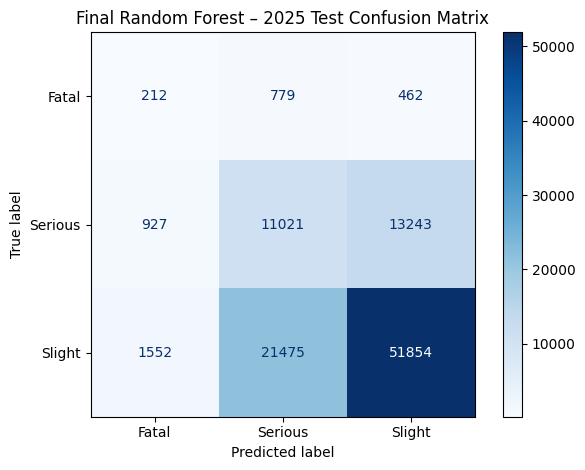

In [ ]:
cm_test = confusion_matrix(y_test, y_test_pred, labels=[1, 2, 3])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_test,
    display_labels=['Fatal', 'Serious', 'Slight']
)
disp.plot(cmap='Blues', values_format='d')
plt.title('Final Random Forest – 2025 Test Confusion Matrix')
plt.tight_layout()
plt.show()

## Step 41 – Create and save the 2025 prediction results

This table contains actual severity, predicted severity, and the model probability for each predicted class. The probabilities are model estimates, not guaranteed real-world probabilities.

In [ ]:

# ============================================================
# PART 4: SAVE FINAL 2025 RANDOM FOREST PREDICTIONS
# ============================================================

severity_names = {
    1: 'Fatal',
    2: 'Serious',
    3: 'Slight'
}

# Generate predictions using the final trained Random Forest model
test_pred_default = final_model.predict(X_test_processed)

# Generate class probabilities
y_test_proba = final_model.predict_proba(X_test_processed)

# Get class positions from the trained model
classes = list(final_model.classes_)

fatal_idx = classes.index(1)
serious_idx = classes.index(2)
slight_idx = classes.index(3)

# Create prediction results DataFrame
prediction_results = pd.DataFrame({

    # Actual severity
    'actual_severity': np.asarray(y_test),

    # Random Forest predictions
    'predicted_severity': test_pred_default,

    # Readable severity labels
    'actual_severity_name': pd.Series(
        np.asarray(y_test)
    ).map(severity_names).to_numpy(),

    'predicted_severity_name': pd.Series(
        test_pred_default
    ).map(severity_names).to_numpy(),

    # Random Forest class probabilities
    'probability_fatal': y_test_proba[:, fatal_idx],
    'probability_serious': y_test_proba[:, serious_idx],
    'probability_slight': y_test_proba[:, slight_idx]
})

# Check prediction correctness
prediction_results['prediction_correct'] = (
    prediction_results['actual_severity'] ==
    prediction_results['predicted_severity']
)

# Display first five predictions
print("Final Random Forest Prediction Results:")
display(prediction_results.head())

# Verify prediction performance
print("\nTotal test records:", len(prediction_results))

print(
    "Final Random Forest accuracy:",
    prediction_results['prediction_correct'].mean()
)

# Save prediction results
output_path = save_path

prediction_results.to_csv(
    os.path.join(output_path, '2025_test_predictions.csv'),
    index=False
)

# Save final trained Random Forest model
joblib.dump(
    final_model,
    os.path.join(output_path, 'final_random_forest_model.pkl')
)

print("\nSaved final Random Forest predictions and model to:", output_path)


Final Random Forest Prediction Results:


,actual_severity,predicted_severity,actual_severity_name,predicted_severity_name,probability_fatal,probability_serious,probability_slight,prediction_correct
0,3,3,Slight,Slight,0.096608,0.435230,0.468162,True
1,3,3,Slight,Slight,0.054339,0.436647,0.509015,True
2,3,3,Slight,Slight,0.100040,0.382721,0.517239,True
3,3,2,Slight,Serious,0.238963,0.392837,0.368199,False
4,3,3,Slight,Slight,0.209734,0.348480,0.441785,True



Total test records: 101525
Final Random Forest accuracy: 0.6213937453829106

Saved final Random Forest predictions and model to: /content/drive/MyDrive/Main project/notebooks/processed_data
